In [2]:
!pip install -q ultralytics gradio

In [3]:
import torch
import cv2
import numpy as np
import matplotlib.pyplot as plt

from ultralytics import YOLO
from collections import Counter
from PIL import Image
from google.colab import files

print("GPU Available:", torch.cuda.is_available())

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
GPU Available: True


In [4]:
model = YOLO("yolo11n.pt")

print("YOLO model loaded successfully")

YOLO model loaded successfully


Saving Screenshot 2025-03-18 130409.jpg to Screenshot 2025-03-18 130409.jpg


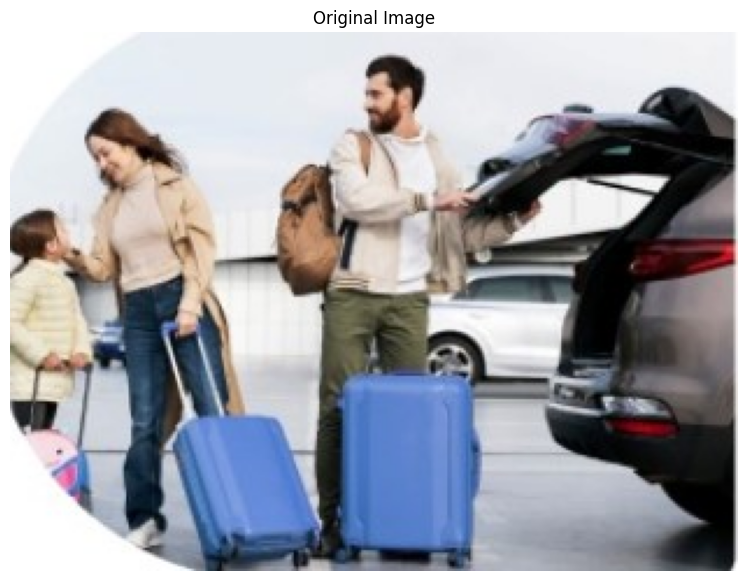

In [15]:
uploaded = files.upload()

image_path = next(iter(uploaded))

image = Image.open(image_path).convert("RGB")

plt.figure(figsize=(10, 7))
plt.imshow(image)
plt.title("Original Image")
plt.axis("off")
plt.show()


In [16]:
results = model.predict(
    source = image_path,
    conf = 0.25,
    save = False
)

result = results[0]

print("dETECTION cOMPLETED")


image 1/1 /content/Screenshot 2025-03-18 130409.jpg: 480x640 4 persons, 2 cars, 1 backpack, 2 suitcases, 23.4ms
Speed: 2.8ms preprocess, 23.4ms inference, 17.5ms postprocess per image at shape (1, 3, 480, 640)
dETECTION cOMPLETED


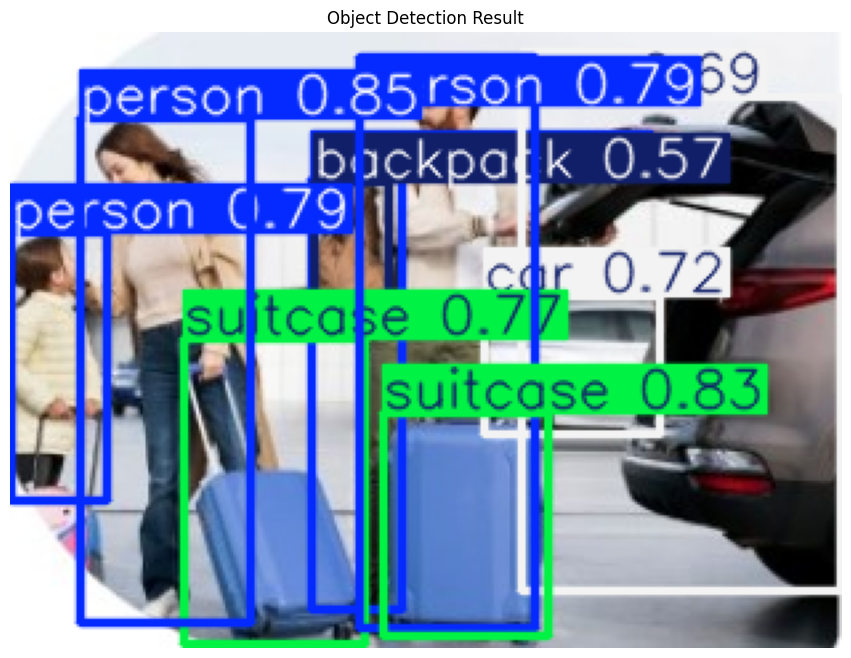

In [17]:
annotated_image = result.plot()

annotated_image = cv2.cvtColor(
    annotated_image,
    cv2.COLOR_BGR2RGB
)

plt.figure(figsize=(12, 8))
plt.imshow(annotated_image)
plt.title("Object Detection Result")
plt.axis("off")
plt.show()

In [18]:
detected_objects = []

for box in result.boxes:

    class_id = int(box.cls[0])

    class_name = model.names[class_id]

    detected_objects.append(class_name)

object_counts = Counter(detected_objects)

print("Detected Object Summary")

for name, count in object_counts.items():

    print(name, ":", count)

print("Total Objects:", len(detected_objects))

Detected Object Summary
person : 4
suitcase : 2
car : 2
backpack : 1
Total Objects: 9


In [19]:
for box in result.boxes:

    class_id = int(box.cls[0])

    class_name = model.names[class_id]

    confidence = float(box.conf[0])

    print(
        f"{class_name}: {confidence:.2%}"
    )

person: 85.22%
suitcase: 83.38%
person: 79.43%
person: 78.88%
suitcase: 76.78%
car: 72.46%
car: 69.20%
backpack: 57.30%
person: 32.41%


In [20]:
output_path = "object_detection_result.jpg"

Image.fromarray(annotated_image).save(output_path)

files.download(output_path)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [21]:
import gradio as gr

def detect_objects(input_image):

    results = model.predict(
        source=input_image,
        conf=0.25
    )

    result = results[0]

    annotated = result.plot()

    annotated = cv2.cvtColor(
        annotated,
        cv2.COLOR_BGR2RGB
    )

    names = [
        model.names[int(box.cls[0])]
        for box in result.boxes
    ]

    counts = Counter(names)

    summary = "\n".join(
        f"{name}: {count}"
        for name, count in counts.items()
    )

    if not summary:
        summary = "No objects detected."

    summary += f"\n\nTotal objects: {len(names)}"

    return annotated, summary

demo = gr.Interface(
    fn=detect_objects,
    inputs=gr.Image(type="pil", label="Upload Image"),
    outputs=[
        gr.Image(label="Detection Result"),
        gr.Textbox(label="Object Counts")
    ],
    title="Smart Object Detection System",
    description="Upload an image to detect and count objects using YOLO."
)

demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://72047b09163b3bbc56.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
